# Exercises and objectives

A) Load the magnetoencephalographic recordings and do some initial plots to understand the data  
B) Do logistic regression to classify pairs of PAS-ratings and all four-PAS-ratings 

REMEMBER: In your portfolio, make sure to include code that can reproduce the answers requested in the exercises below (**EXPORT A VERSION**). If it cannot be exported, it cannot be part of your portfolio

# EXERCISE A - Load the magnetoencephalographic recordings and do some initial plots to understand the data  

The files `megmag_data.npy` and `pas_vector.npy` can be downloaded here (http://laumollerandersen.org/data_methods_3/megmag_data.npy) and here (http://laumollerandersen.org/data_methods_3/pas_vector.npy)   

1) Load `megmag_data.npy` and call it `data` using `np.load`. You can use `join`, which can be imported from `os.path`, to create paths from different string segments  


In [63]:
import os 
import numpy as np

#We load in the data from the current directory
path = os.getcwd()

megmag_path = os.path.join(path, "megmag_data.npy")

data = np.load(megmag_path)



&nbsp;&nbsp;&nbsp;&nbsp;   i. The data is a 3-dimensional array. The first dimension is number of repetitions of a visual stimulus , the second dimension is the number of sensors that record magnetic fields (in Tesla) that stem from neurons activating in the brain, and the third dimension is the number of time samples. How many repetitions, sensors and time samples are there?  

*Anser:* We can get the number og repetitions, sensors and time samples by calling .sample on the megmag data. 

In [64]:
print(data.shape)

(682, 102, 251)


We know that the data is in order of repetitions, sensors and time samples, so we know that the there is 682 repetitions, 102 sensors, and 251 time samples. The pas data also confirms the amount of repetitions being 682, since we have one answer per repetition. 


&nbsp;&nbsp;&nbsp;&nbsp;    ii. The time range is from (and including) -200 ms to (and including) 800 ms with a sample recorded every 4 ms. (At time 0, the visual stimulus was briefly presented). Create a 1-dimensional array called `times` that represents this. 

*Answer:* We do this using `range()` and converting to an array.  

In [65]:
#we do this using the range function and adding +1 since range is not inclusive
times = np.array(range(-200, 800 + 1, 4))

print(times)

[-200 -196 -192 -188 -184 -180 -176 -172 -168 -164 -160 -156 -152 -148
 -144 -140 -136 -132 -128 -124 -120 -116 -112 -108 -104 -100  -96  -92
  -88  -84  -80  -76  -72  -68  -64  -60  -56  -52  -48  -44  -40  -36
  -32  -28  -24  -20  -16  -12   -8   -4    0    4    8   12   16   20
   24   28   32   36   40   44   48   52   56   60   64   68   72   76
   80   84   88   92   96  100  104  108  112  116  120  124  128  132
  136  140  144  148  152  156  160  164  168  172  176  180  184  188
  192  196  200  204  208  212  216  220  224  228  232  236  240  244
  248  252  256  260  264  268  272  276  280  284  288  292  296  300
  304  308  312  316  320  324  328  332  336  340  344  348  352  356
  360  364  368  372  376  380  384  388  392  396  400  404  408  412
  416  420  424  428  432  436  440  444  448  452  456  460  464  468
  472  476  480  484  488  492  496  500  504  508  512  516  520  524
  528  532  536  540  544  548  552  556  560  564  568  572  576  580
  584 


&nbsp;&nbsp;&nbsp;&nbsp;  iii. Create the sensor covariance matrix $\Sigma_{XX}$: $$\Sigma_{XX} = \frac 1 N \sum_{i=1}^N XX^T$$ $N$ is the number of repetitions and $X$ has $s$ rows and $t$ columns (sensors and time), thus the shape is $X_{s\times t}$. Do the sensors pick up independent signals? (Use `plt.imshow` to plot the sensor covariance matrix)  
    
*Answer:* We are able to do this by looping over the repetitions in the array and summing until we are finished and we can divide by the repetitions:

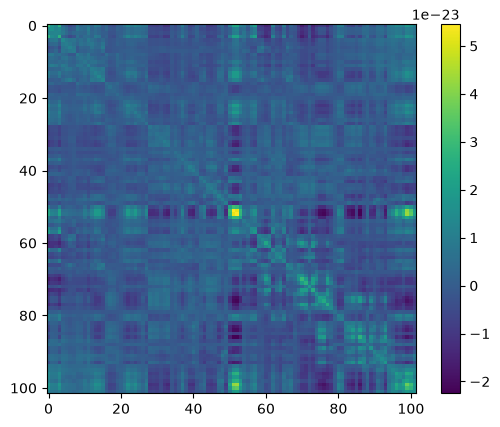

In [66]:
import matplotlib.pyplot as plt

sum = 0
repetitions = len(range(data.shape[0]))
for i in range(repetitions): #we loop over the repetitions
    sum += np.dot(data[i], np.transpose(data[i]))

covariance_matrix = sum / repetitions

plt.imshow(covariance_matrix)
plt.colorbar()

&nbsp;&nbsp;&nbsp;&nbsp; iv. Make an average over the repetition dimension using `np.mean` - use the `axis` argument. (The resulting array should have two dimensions  with sensor as the first and time as the second)  
    
*Answer:* We do this using `np.mean` and using the `axis` argument as suggested.  

In [67]:
mean_array = np.mean(data, axis = 0)

print(mean_array.shape) # we see the correct size

(102, 251)


&nbsp;&nbsp;&nbsp;&nbsp;    v. Plot the magnetic field (based on the average) as it evolves over time for each of the sensors (a line for each) (time on the x-axis and magnetic field on the y-axis). Add a horizontal line at $y = 0$ and a vertical line at $x = 0$ using `plt.axvline` and `plt.axhline`  

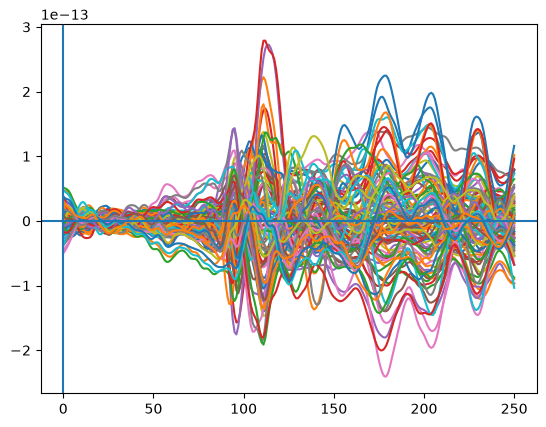

In [68]:
for i in range(mean_array.shape[0]):
    plt.plot(mean_array[i,:])
plt.axvline(0)
plt.axhline(0)

&nbsp;&nbsp;&nbsp;&nbsp;    vi. Find the maximal magnetic field in the average. Then use `np.argmax` and `np.unravel_index` to find the sensor that has the maximal magnetic field.  

In [69]:
max_mag = np.max(mean_array)
print(max_mag)
argmax_value = np.argmax(mean_array)
print(argmax_value)
max_mag_sensor = np.unravel_index(argmax_value, mean_array.shape)
print(max_mag_sensor)

2.7886216843591933e-13
18435
(np.int64(73), np.int64(112))


The first dimension of the `mean_array` is the sensors, so we know that sensor 73 got the highest magnetic field value at time 112.

&nbsp;&nbsp;&nbsp;&nbsp;    vii. Plot the magnetic field for each of the repetitions (a line for each) for the sensor that has the maximal magnetic field. Highlight the time point with the maximal magnetic field in the average (as found in A.1.v) using `plt.axvline`  

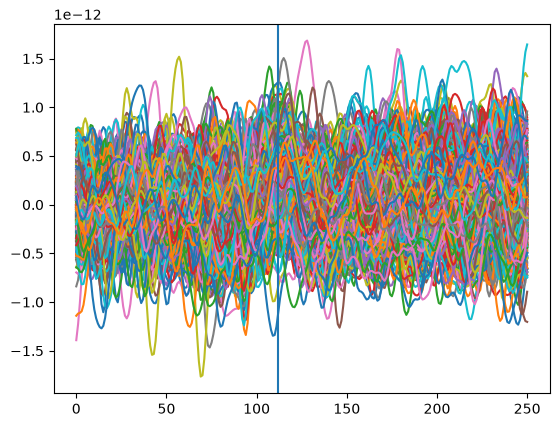

In [70]:
max_sensor = data[:,73,:]
for i in range(max_sensor.shape[0]):
    plt.plot(max_sensor[i,:])

plt.axvline(max_mag_sensor[1])

&nbsp;&nbsp;&nbsp;&nbsp;    viii. Describe in your own words how the response found in the average is represented in the single repetitions. But do make sure to use the concepts _signal_ and _noise_ and comment on any differences on the range of values on the y-axis  


    
2) Now load `pas_vector.npy` (call it `y`). PAS is the same as in Assignment 1, describing the clarity of the subjective experience the subject reported after seeing the briefly presented stimulus  

In [71]:
pas_path = os.path.join(path, "pas_vector.npy")

y = np.load(pas_path)

&nbsp;&nbsp;&nbsp;&nbsp;    i. Which dimension in the `data` array does it have the same length as?

In [72]:
print(data.shape)

print(y.shape)

(682, 102, 251)
(682,)


It has the same length as the repetitions since it holds what type of condition we were doing in the repetition we were doing.

&nbsp;&nbsp;&nbsp;&nbsp;    ii. Now make four averages (As in Exercise A.1.iv), one for each PAS rating, and plot the four time courses (one for each PAS rating) for the sensor found in Exercise A.1.vi

In [73]:
pas_1 = np.mean(data[y == 1], axis = 0)
pas_2 = np.mean(data[y == 2], axis = 0)

print(pas_1.shape) # we see the correct size

(102, 251)


&nbsp;&nbsp;&nbsp;&nbsp;    iii. Notice that there are two early peaks (measuring visual activity from the brain), one before 200 ms and one around 250 ms. Describe how the amplitudes of responses are related to the four PAS-scores. Does PAS 2 behave differently than expected? 

 # EXERCISE B - Do logistic regression to classify pairs of PAS-ratings  

1) Now, we are going to do Logistic Regression with the aim of classifying the PAS-rating given by the subject  
&nbsp;&nbsp;&nbsp;&nbsp;    i. We'll start with a binary problem - create a new array called `data_1_2` that only contains PAS responses 1 and 2. Similarly, create a `y_1_2` for the target vector
  


In [74]:
data_1_2 = data[ (y == 1) | (y == 2)]
y_1_2 = y[(y == 1) | (y == 2)]
print(data_1_2.shape, y_1_2.shape)

(214, 102, 251) (214,)


&nbsp;&nbsp;&nbsp;&nbsp;    ii. Scikit-learn expects our observations (`data_1_2`) to be in a 2d-array, which has samples (repetitions) on dimension 1 and features (predictor variables) on dimension 2. Our `data_1_2` is a three-dimensional array. Our strategy will be to collapse our two last dimensions (sensors and time) into one dimension, while keeping the first dimension as it is (repetitions). Use `np.reshape` to create a variable `X_1_2` that fulfils these criteria.
  

In [75]:
X_1_2 = data_1_2.reshape((data_1_2.shape[0], data_1_2.shape[1] * data_1_2.shape[2]))
print(X_1_2.shape)

(214, 25602)


&nbsp;&nbsp;&nbsp;&nbsp;    iii. Import the `StandardScaler` and scale `X_1_2`  

In [76]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_1_2 = scaler.fit_transform(X_1_2)

print(X_1_2)

[[-1.52371533 -1.41962232 -1.25380488 ...  0.52014766  0.68510079
   0.95926262]
 [ 1.66444245  1.55041052  1.33299785 ...  0.80497214  0.67868331
   0.56314609]
 [-1.53870418 -1.61521213 -1.33925051 ...  0.74824436  0.80282669
   0.84924931]
 ...
 [-0.80940809 -0.59414428 -0.12880611 ...  0.17635857  0.20292317
   0.275932  ]
 [-0.48386092 -0.31604499 -0.26050482 ... -2.87939867 -3.10176024
  -3.19853114]
 [-0.01665374  0.42092075  0.9110782  ... -0.85189478 -1.04233282
  -1.19717065]]


&nbsp;&nbsp;&nbsp;&nbsp;    iv. Do a standard `LogisticRegression` - can be imported from `sklearn.linear_model` - make sure there is no `penalty` applied  

In [77]:
from sklearn.linear_model import LogisticRegression

from sklearn.model_selection import train_test_split

lg = LogisticRegression(random_state = 1) #by default there is no penalty added

lg.fit(X_1_2, y_1_2)


,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",1
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver

&nbsp;&nbsp;&nbsp;&nbsp;    v. Use the `score` method of `LogisticRegression` to find out how many labels were classified correctly. Are we overfitting? Besides the score, what would make you suspect that we are overfitting?  

In [78]:
y_pred = lg.predict(X_1_2) #We predict the results on the training data
print('Test Accuracy: %.3f' % lg.score(X_1_2, y_1_2)) #Accuracy on the training data

Test Accuracy: 1.000


There is bound to be some noise in the training data and we wouldn't want to also capture that, so the fact that we get an accuracy of 100% means that we are most likely also capturing the noise, which is overfitting. 

&nbsp;&nbsp;&nbsp;&nbsp;    vi. Now apply the _L1_ penalty instead, using the default C, - how many of the coefficients (`.coef_`) are non-zero after this?  

In [79]:
lg_penalty = LogisticRegression(random_state=1, l1_ratio=1, solver = 'liblinear')

lg_penalty.fit(X_1_2, y_1_2) # fitting the data to the new logistic regression object

#summing all instances of coefficients not being zero and comparing the the 
print(np.sum((lg_penalty.coef_ != 0) == True), "out of", len(lg_penalty.coef_[0])) 

282 out of 25602


We see that there are 282 out of 25602 coefficients that are not zero. 


&nbsp;&nbsp;&nbsp;&nbsp;    vii. Create a new reduced $X$ that only includes the non-zero coefficients - show the covariance of the non-zero features; $X_{reduced}X_{reduced}^T$ . Plot the covariance of the features using `plt.imshow`. Compared to a covariance-plot where you do not use any penalties, do you see less covariance? (Ignore the absolute values, but look at the pattern)



2) Now, we are going to build better (more predictive) models by using cross-validation as an outcome measure

&nbsp;&nbsp;&nbsp;&nbsp;    i. Import `cross_val_score` and `StratifiedKFold` from `sklearn.model_selection`  


In [80]:
from sklearn.model_selection import cross_val_score, StratifiedKFold


&nbsp;&nbsp;&nbsp;&nbsp;    ii. To make sure that our training data sets are not biased to one target (PAS) or the other, create `y_1_2_equal`, which should have an equal number of each target. Create a similar `X_1_2_equal`. The function `equalize_targets_binary` in the code chunk associated with Exercise B.2.ii can be used. Remember to scale the training and test datasets created from `X_1_2_equal`!  


In [81]:
# Exercise B.2.ii
def equalize_targets_binary(data, y, dimensions = 2):
    np.random.seed(7)
    targets = np.unique(y) ## find the number of targets
    if len(targets) > 2:
        raise NameError("can't have more than two targets")
    counts = list()
    indices = list()
    for target in targets:
        counts.append(np.sum(y == target)) ## find the number of each target
        indices.append(np.where(y == target)[0]) ## find their indices
    min_count = np.min(counts)
    # randomly choose trials
    first_choice = np.random.choice(indices[0], size=min_count, replace=False)
    second_choice = np.random.choice(indices[1], size=min_count,replace=False)
    
    # create the new data sets
    new_indices = np.concatenate((first_choice, second_choice))
    new_y = y[new_indices]
    #because we have to deal with a different amount of dimensions at a different time
    #we add a choice between having 2 or 3 dimensions
    if (dimensions == 2):
        new_data = data[new_indices, :] 
    elif(dimensions == 3):
        new_data = data[new_indices, :, :]
    
    return new_data, new_y

X_1_2_equal, y_1_2_equal = equalize_targets_binary(X_1_2, y_1_2)

#We create our train, test split 

X_train, X_test, y_train, y_test = train_test_split(X_1_2_equal, y_1_2_equal, test_size=0.2)

#We remember to scale later on by using a pipe.




&nbsp;&nbsp;&nbsp;&nbsp;    iii. Do cross-validation with 5 stratified folds doing standard `LogisticRegression` (See Exercise B.1.iv)  


In [82]:
from sklearn.model_selection import cross_validate
from sklearn.pipeline import make_pipeline
pipe_lg = make_pipeline(StandardScaler(), LogisticRegression())

#We get the results of our cross validation
cv_results = cross_validate(pipe_lg, X_train, y_train, cv = 5)

#we get the "test" score (that is really a validation score) to see how well it did 
#for the different splits. 
print(cv_results["test_score"]) 

[0.6875     0.59375    0.375      0.70967742 0.61290323]


______________________________________________________ ALF __________________________________________________________


&nbsp;&nbsp;&nbsp;&nbsp;    iv. Do L2-regularisation with the following `Cs=[1e5, 1e1, 1e-5]`. Use the same kind of cross-validation as in Exercise B.2.iii. In the best-scoring of these models, how many more/fewer predictions are correct (on average)?  


In [83]:
from sklearn.model_selection import cross_val_predict

for i in [1e5, 1e1, 1e-5]:
    pipe_lg = make_pipeline(StandardScaler(), LogisticRegression(l1_ratio=0, C = i)) #l2 regularization
    #We get the results of our cross validation.
    #This is the same type of validation, but with a different function.
    y_pred = cross_val_predict(pipe_lg, X_train, y_train, cv = 5)

    n_correct = np.sum(y_pred == y_train)

    n_total = len(y_train)

    print(f"the model cs = {i} got {n_correct} out of {n_total} correct")

the model cs = 100000.0 got 85 out of 158 correct
the model cs = 10.0 got 87 out of 158 correct
the model cs = 1e-05 got 82 out of 158 correct


The model with Cs = 1e1 had a slightly higher average score than the others - it had about 2 more correct predictions than Cs = 1e5 and 5 more than Cs = 1e-5.


&nbsp;&nbsp;&nbsp;&nbsp;    v. Instead of fitting a model on all `n_sensors * n_samples` features, fit a logistic regression (same kind as in Exercise B.2.iv (use the `C` that resulted in the best prediction)) for __each__ time sample and use the same cross-validation as in Exercise B.2.iii. What are the time points where classification is best? Make a plot with time on the x-axis and classification score on the y-axis with a horizontal line at the chance level (what is the chance level for this analysis?)  


In [84]:
#we make a large max_iter because the model otherwise does not converge
pipe_lg = make_pipeline(StandardScaler(), LogisticRegression(l1_ratio = 0, C = 1e1, max_iter=1000))
scores = []

#equalizing the data, now with 3 dimensions
X_1_2_equal, y_1_2_equal = equalize_targets_binary(data_1_2, y_1_2, dimensions = 3)

#We create our train, test split 
X_train, X_test, y_train, y_test = train_test_split(X_1_2_equal, y_1_2_equal, test_size=0.2)

time_length = data_1_2.shape[2]

for i in range(time_length):
    scores.append(np.mean(cross_val_score(pipe_lg, X_train[:,:,i], y_train)))


The time value with the highest score was [107 106 105 164]


Text(0, 0.5, 'accuracy')

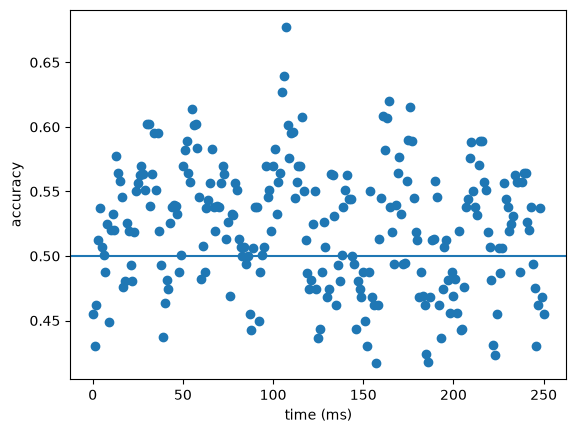

In [ ]:
#We use argsort[::-1] to get the highest indices in decreasing order
# and we take the first four values
print(f"The time values with the highest score were {np.argsort(scores)[::-1][:4]}") 
plt.scatter(x = range(time_length), y = scores)
plt.axhline(0.5) #in an equalized binary classification our random guessing is at a 50% chance
plt.xlabel("time (ms)")
plt.ylabel("accuracy")



&nbsp;&nbsp;&nbsp;&nbsp;vi. Now do the same, but with L1 regression - set `C=1e-1` - what are the time points when classification is best? (make a plot)?  


In [86]:
from sklearn.model_selection import cross_val_score
#we make a large max_iter because the model otherwise does not converge
pipe_lg = make_pipeline(StandardScaler(), LogisticRegression(l1_ratio = 1, C = 1e-1, solver = 'liblinear', max_iter=1000))
scores = []

#equalizing the data, now with 3 dimensions
X_1_2_equal, y_1_2_equal = equalize_targets_binary(data_1_2, y_1_2, dimensions = 3)

#We create our train, test split 
X_train, X_test, y_train, y_test = train_test_split(X_1_2_equal, y_1_2_equal, test_size=0.2)

time_length = data_1_2.shape[2]

for i in range(time_length):
    scores.append(np.mean(cross_val_score(pipe_lg, X_train[:,:,i], y_train)))


The time value with the highest score was [ 70 101 184  30]


Text(0, 0.5, 'score out of 1')

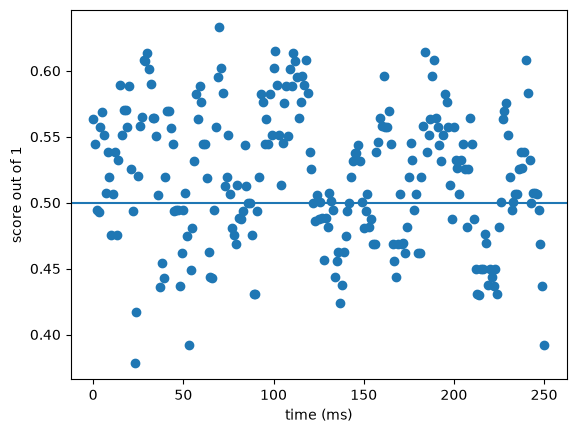

In [ ]:
print(f"The time values with the highest scores were {np.argsort(scores)[::-1][:4]}") 
plt.scatter(x = range(time_length), y = scores)
plt.axhline(0.5) #in an equalized binary classification our random guessing is at a 50% chance
plt.xlabel("time (ms)")
plt.ylabel("score out of 1")



&nbsp;&nbsp;&nbsp;&nbsp; vii. Finally, fit the same models as in Exercise B.2.vi but now for `data_1_4` and `y_1_4` (create a data set and a target vector that only contains PAS responses 1 and 4). What are the time points when classification is best? Make a plot with time on the x-axis and classification score on the y-axis with a horizontal line at the chance level (what is the chance level for this analysis?)  


In [88]:
data_1_4 = data[(y == 1) | (y == 4)]
y_1_4 = y[(y == 1) | (y == 4)]

scores = []

#equalizing the data, now with 3 dimensions
X_1_4_equal, y_1_4_equal = equalize_targets_binary(data_1_4, y_1_4, dimensions = 3)

#We create our train, test split 
X_train, X_test, y_train, y_test = train_test_split(X_1_4_equal, y_1_4_equal, test_size=0.2)

time_length = data_1_4.shape[2]

for i in range(time_length):
    scores.append(np.mean(cross_val_score(pipe_lg, X_train[:,:,i], y_train)))

The time value with the highest score was [136 107 135 134]


Text(0, 0.5, 'score out of 1')

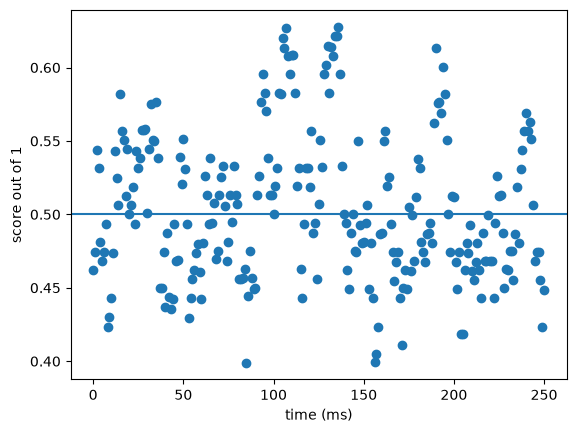

In [ ]:
print(f"The time values with the highest scores were {np.argsort(scores)[::-1][:4]}") 
plt.scatter(x = range(time_length), y = scores)
plt.axhline(0.5) #in an equalized binary classification our random guessing is at a 50% chance
plt.xlabel("time (ms)")
plt.ylabel("score out of 1")


&nbsp;&nbsp;&nbsp;&nbsp;    viii. Is pairwise classification of subjective experience possible? Any surprises in the classification accuracies, i.e. how does the classification score for PAS 1 vs 4 compare to the classification score for PAS 1 vs 2?  

*Answer:* 
We can see above-chance prediction of PAS at around 100 ms for multiple trials, but the results are too noisy and unsure for us to conclude that pairwise classification of subjective experience may be possible. Interestingly, both plots of 1v2 and 1v4 predictions look very similar, although their subjective experiences are very far from each other. One would perhaps suspect that the difference in brain signals between 1 and 2 and 1 and 4 should be bigger for 1 and 4, but we were not able to show that in our results here. 